# Notebook 5 – Baselines and ML Models

In [1]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")
REPO = "India-Demand-Forecasting-ML"
BRANCH = "feature/features-and-models"
if not os.path.exists(REPO):
    !git clone -b {BRANCH} https://github.com/tanishmaity03/India-Demand-Forecasting-ML.git
%cd {REPO}
!pip install -q holidays
sys.path.append(".")

import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from src.features import build_features, FEATURE_SETS
from src.evaluate import split_mask, metrics

sns.set_theme(style="whitegrid"); pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
Path("results/figures").mkdir(parents=True, exist_ok=True); Path("results/tables").mkdir(parents=True, exist_ok=True)
df = pd.read_csv("data/processed/india_demand_weather.csv", parse_dates=["datetime"])

Cloning into 'India-Demand-Forecasting-ML'...
remote: Enumerating objects: 121, done.
remote: Counting objects: 100% (121/121), done.
remote: Compressing objects: 100% (94/94), done.
remote: Total 121 (delta 31), reused 108 (delta 20), pack-reused 0 (from 0)
Receiving objects: 100% (121/121), 19.86 MiB | 12.35 MiB/s, done.
Resolving deltas: 100% (31/31), done.
/content/India-Demand-Forecasting-ML


In [2]:
def make_models():
    return {
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Random Forest": RandomForestRegressor(n_estimators=150, min_samples_leaf=5, max_features=0.5,
                                               n_jobs=-1, random_state=42),
        "Gradient Boosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.06, random_state=42),
    }

In [3]:
rows, preds, fitted, datasets = [], {}, {}, {}
for h in (1, 24):
    ds = build_features(df, h, "full"); datasets[h] = ds
    tr, va = split_mask(ds.target_time, "train"), split_mask(ds.target_time, "val")

    for b in ds.baselines.columns:
        rows.append({"horizon_h": h, "model": f"Baseline: {b}", **metrics(ds.y_true[va], ds.baselines[b][va])})

    for name, model in make_models().items():
        t0 = time.time()
        model.fit(ds.X[tr], ds.y_rel[tr])                               # trained on relative demand
        pred = model.predict(ds.X[va]) * ds.level[va].values            # back to MW
        preds[(h, name)] = pd.Series(pred, index=ds.y_true[va].index)
        fitted[(h, name)] = model
        rows.append({"horizon_h": h, "model": name, **metrics(ds.y_true[va], pred)})
        print(f"h={h} {name}: fitted in {time.time()-t0:.0f}s")

res = pd.DataFrame(rows)
best_base = res[res["model"].str.startswith("Baseline")].groupby("horizon_h")["MAE (MW)"].min()
res["Skill vs best baseline (%)"] = (1 - res["MAE (MW)"] / res["horizon_h"].map(best_base)) * 100
res = res.round(3)
res.to_csv("results/tables/model_comparison_validation.csv", index=False)
res

h=1 Linear Regression: fitted in 0s
h=1 Random Forest: fitted in 49s
h=1 Gradient Boosting: fitted in 3s
h=24 Linear Regression: fitted in 0s
h=24 Random Forest: fitted in 43s
h=24 Gradient Boosting: fitted in 4s


,horizon_h,model,MAE (MW),RMSE (MW),MAPE (%),R2,Skill vs best baseline (%)
0,1,Baseline: persistence,3703.704,4876.509,2.252,0.929,0.000
1,1,Baseline: previous_day,4078.771,5711.490,2.449,0.903,-10.127
2,1,Baseline: previous_week,6071.486,8375.057,3.657,0.791,-63.930
3,1,Linear Regression,917.980,1350.438,0.542,0.995,75.215
4,1,Random Forest,1183.485,1650.645,0.702,0.992,68.046
5,1,Gradient Boosting,1033.902,1455.379,0.615,0.994,72.085
6,24,Baseline: persistence,4078.771,5711.490,2.449,0.903,0.000
7,24,Baseline: previous_day,4078.771,5711.490,2.449,0.903,0.000
8,24,Baseline: previous_week,6071.486,8375.057,3.657,0.791,-48.856
9,24,Linear Regression,3250.002,4480.372,1.963,0.940,20.319


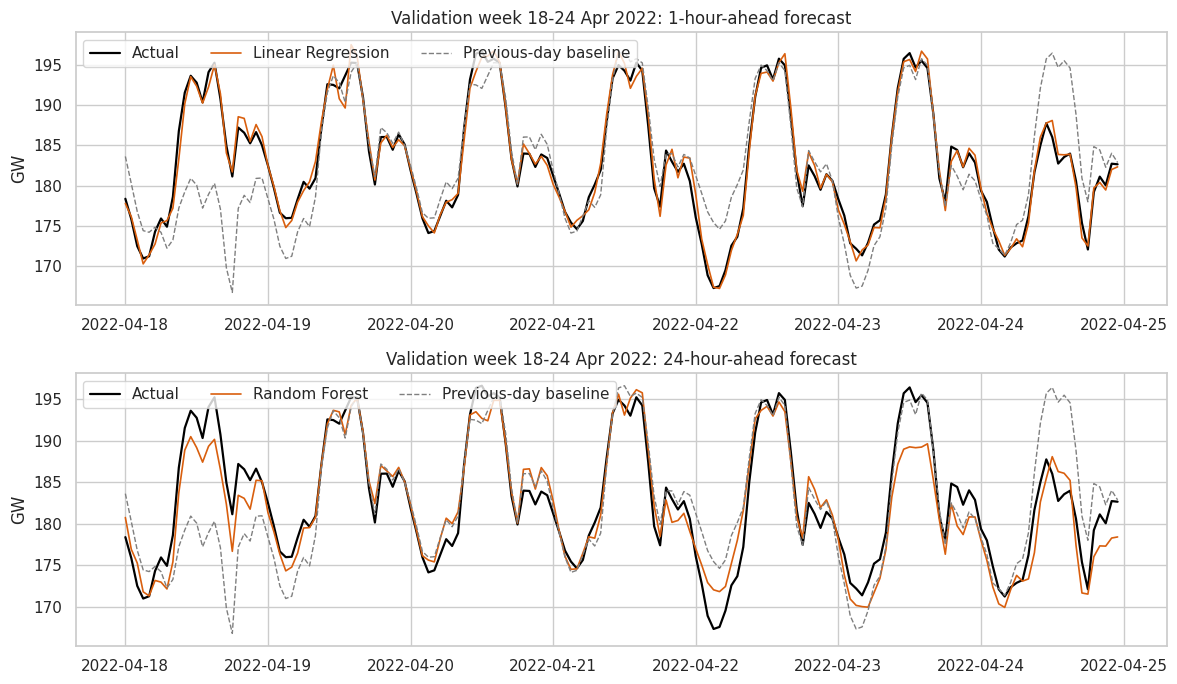

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, h in zip(axes, (1, 24)):
    ds = datasets[h]; va = split_mask(ds.target_time, "val")
    ml = res[(res.horizon_h == h) & (~res.model.str.startswith("Baseline"))].sort_values("MAE (MW)").iloc[0]["model"]
    week = ds.y_true[va].index[(ds.target_time[va] >= "2022-04-18") & (ds.target_time[va] < "2022-04-25")]
    tt = ds.target_time[week]
    ax.plot(tt, ds.y_true[week] / 1000, label="Actual", color="black", lw=1.6)
    ax.plot(tt, preds[(h, ml)][week] / 1000, label=ml, color="#d95f0e", lw=1.2)
    ax.plot(tt, ds.baselines["previous_day"][week] / 1000, label="Previous-day baseline", color="#7f7f7f", lw=1, ls="--")
    ax.set_title(f"Validation week 18-24 Apr 2022: {h}-hour-ahead forecast"); ax.set_ylabel("GW"); ax.legend(loc="upper left", ncol=3)
plt.tight_layout()
plt.savefig("results/figures/05_actual_vs_predicted_validation_week.png", dpi=150)
plt.show()

In [5]:
abl = []
for h in (1, 24):
    for fs in FEATURE_SETS:
        ds = build_features(df, h, fs)
        tr, va = split_mask(ds.target_time, "train"), split_mask(ds.target_time, "val")
        m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.06, random_state=42).fit(ds.X[tr], ds.y_rel[tr])
        p = m.predict(ds.X[va]) * ds.level[va].values
        abl.append({"horizon_h": h, "feature_set": fs, "n_features": ds.X.shape[1], **metrics(ds.y_true[va], p)})
abl = pd.DataFrame(abl).round(3)
abl.to_csv("results/tables/ablation_feature_sets_validation.csv", index=False)
abl

,horizon_h,feature_set,n_features,MAE (MW),RMSE (MW),MAPE (%),R2
0,1,demand,16,1075.451,1525.801,0.642,0.993
1,1,calendar,25,1032.534,1450.214,0.614,0.994
2,1,full,34,1033.902,1455.379,0.615,0.994
3,24,demand,15,3498.339,4910.206,2.104,0.928
4,24,calendar,24,2993.228,4210.942,1.800,0.947
5,24,full,33,2902.278,4043.621,1.745,0.951


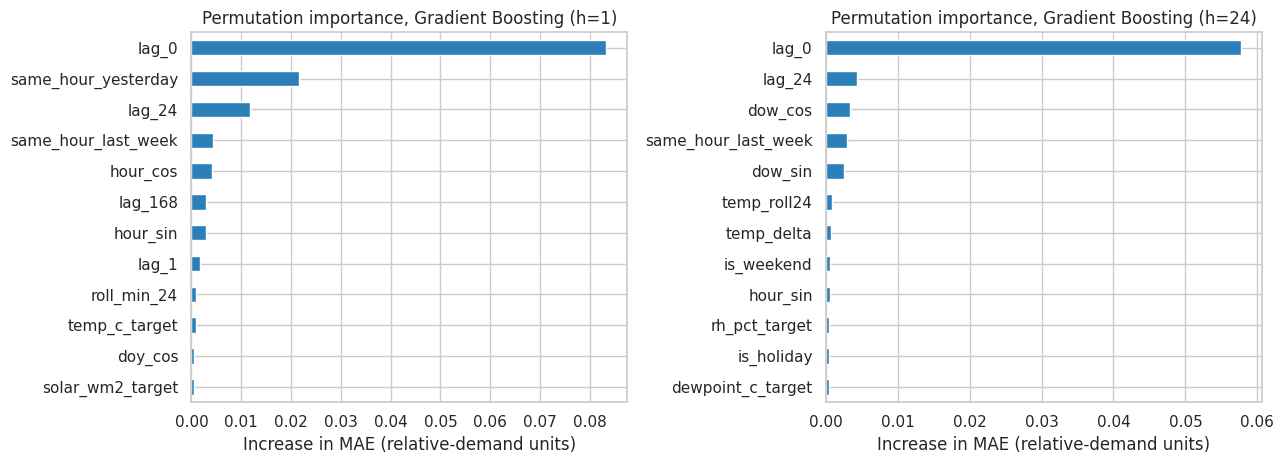

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); imp_rows = []
for ax, h in zip(axes, (1, 24)):
    ds = datasets[h]; va = split_mask(ds.target_time, "val")
    pi = permutation_importance(fitted[(h, "Gradient Boosting")], ds.X[va], ds.y_rel[va], n_repeats=3,
                                random_state=42, scoring="neg_mean_absolute_error", n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=ds.X.columns).sort_values(ascending=False)
    imp.head(12).iloc[::-1].plot.barh(ax=ax, color="#2c7fb8")
    ax.set_title(f"Permutation importance, Gradient Boosting (h={h})")
    ax.set_xlabel("Increase in MAE (relative-demand units)")
    imp_rows.append(imp.head(12).rename("importance").reset_index().assign(horizon_h=h))
plt.tight_layout()
plt.savefig("results/figures/05_permutation_importance.png", dpi=150)
plt.show()
pd.concat(imp_rows).round(5).to_csv("results/tables/permutation_importance_validation.csv", index=False)

## Findings (validation year 2022)
- At 1 h ahead the persistence baseline is the strongest simple baseline (MAE 3,704 MW, 2.25% MAPE); at 24 h the
  previous-day baseline is identical to persistence (MAE 4,079 MW, 2.45% MAPE).
- Best ML model at 1 h: <FILL IN> (MAE <..> MW, <..>% better than the best baseline).
- Best ML model at 24 h: <FILL IN> (MAE <..> MW, <..>% better than the best baseline).
- Adding calendar/holiday features reduces 24 h MAE from ~3,496 to ~2,984 MW (Gradient Boosting).
- Adding weather changes 24 h MAE to <FILL IN from the ablation 'full' row>.
- Most important features: <FILL IN from the permutation importance plot>.
- Limitation: weather at the target time is actual weather, a stand-in for a forecast, so weather gains are optimistic.
- Hyperparameter tuning and time-series cross-validation are done in Notebook 6, followed by the one-time test evaluation.

In [7]:
!zip -qr /content/day3_models_outputs.zip results
from google.colab import files
files.download("/content/day3_models_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>